# Datos torturados: veinte dados legales

**Jornada 3 · Bloque 3.4 · Falsas alarmas y datos torturados**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

dados = lab.cargar_dados(DATOS)
sospechoso = dados.loc[dados["p-valor"] < 0.05, "Dado"].tolist()
print(f"Datos listos: {len(dados)} dados del curso; parece trucado el dado {sospechoso[0]}")

Datos listos: 20 dados del curso; parece trucado el dado 10


## La pregunta

Tiramos veinte dados, sesenta veces cada uno, y a cada dado le preguntamos: «¿estás trucado?». Si el
p-valor baja de 0,05, sospechamos. Ninguno está trucado. Adivina cuántos confiesan.

## El experimento

Elige cuántas comparaciones haces (cuántos dados) y pulsa «Repetir» para volver a tirarlos todos. Con
20 dados y la primera tirada salen los dados del caso del curso: el dado 10 «confiesa» con p = 0,009.
Es lo mismo que les pasó a las veinte gominolas de colores y el acné.

Al añadir dados, los primeros siguen siendo los mismos: solo se suman pruebas nuevas.

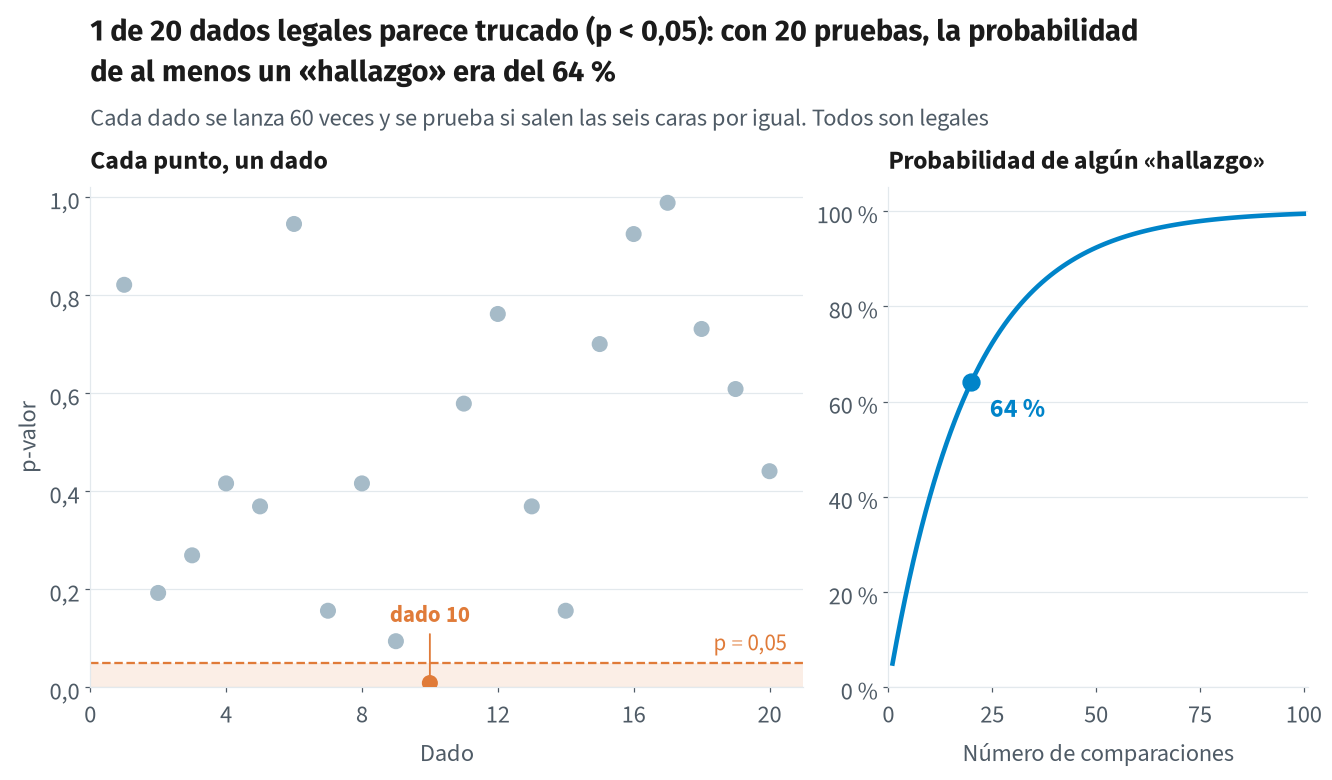

In [2]:
# El experimento: muchos dados legales y una prueba para cada uno.
n = widgets.IntSlider(value=20, min=1, max=100, continuous_update=False,
                      description="Número de comparaciones (dados):", style=ESTILO,
                      layout=widgets.Layout(width="600px"))
semilla = widgets.IntText(value=lab.SEMILLA_DADOS)  # no se ve: la cambian los botones
repetir = widgets.Button(description="Repetir", icon="refresh", button_style="info",
                      layout=widgets.Layout(width="auto"))
volver = widgets.Button(description="Volver a los del curso", icon="undo", layout=widgets.Layout(width="auto"))
repetir.on_click(lambda _: setattr(semilla, "value", semilla.value + 1))
volver.on_click(lambda _: setattr(semilla, "value", lab.SEMILLA_DADOS))


def dibujar(n, semilla):
    lab.mostrar(lab.dibujar_dados(n, semilla))


grafico = widgets.interactive_output(dibujar, {"n": n, "semilla": semilla})
display(widgets.VBox([n, widgets.HBox([repetir, volver]), grafico]))

## Qué observar

1. Con 20 dados, ¿cuántos parecen trucados? Pulsa «Repetir» varias veces: ¿cuántos salen de media?
2. Con un solo dado, ¿qué probabilidad hay de un falso hallazgo? ¿Y con 100?
3. Si el dado 10 parece trucado, ¿qué harías antes de acusarlo? (Pista: volver a tirarlo.)
4. Marketing comparó 20 productos y el muffin de arándanos salió «significativo». ¿Qué le contestarías?

## Mensaje clave

> **Quien busca lo suficiente encuentra algo; eso no lo convierte en verdad.**

La defensa: fijar la pregunta antes de mirar los datos y confirmar con datos nuevos.

## Para curiosos

En el avanzado se corrigen las comparaciones múltiples (Bonferroni, tasa de falsos descubrimientos) para
poder revisar muchas zonas, productos o variables a la vez sin que el azar se cuele como hallazgo.